In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("house_prices.csv")
print("Shape:", df.shape)
df.head()

Shape: (2000, 10)


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [7]:
df.info()
df["Price"].describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Id         2000 non-null   int64 
 1   Area       2000 non-null   int64 
 2   Bedrooms   2000 non-null   int64 
 3   Bathrooms  2000 non-null   int64 
 4   Floors     2000 non-null   int64 
 5   YearBuilt  2000 non-null   int64 
 6   Location   2000 non-null   object
 7   Condition  2000 non-null   object
 8   Garage     2000 non-null   object
 9   Price      2000 non-null   int64 
dtypes: int64(7), object(3)
memory usage: 156.4+ KB


count      2000.000000
mean     537676.855000
std      276428.845719
min       50005.000000
25%      300098.000000
50%      539254.000000
75%      780086.000000
max      999656.000000
Name: Price, dtype: float64

In [9]:
print("Null values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nCategorical columns:")
for c in ["Location", "Condition", "Garage"]:
    print(c, "->", df[c].unique())

Null values per column:
Id           0
Area         0
Bedrooms     0
Bathrooms    0
Floors       0
YearBuilt    0
Location     0
Condition    0
Garage       0
Price        0
dtype: int64

Duplicate rows: 0

Categorical columns:
Location -> ['Downtown' 'Suburban' 'Urban' 'Rural']
Condition -> ['Excellent' 'Good' 'Fair' 'Poor']
Garage -> ['No' 'Yes']


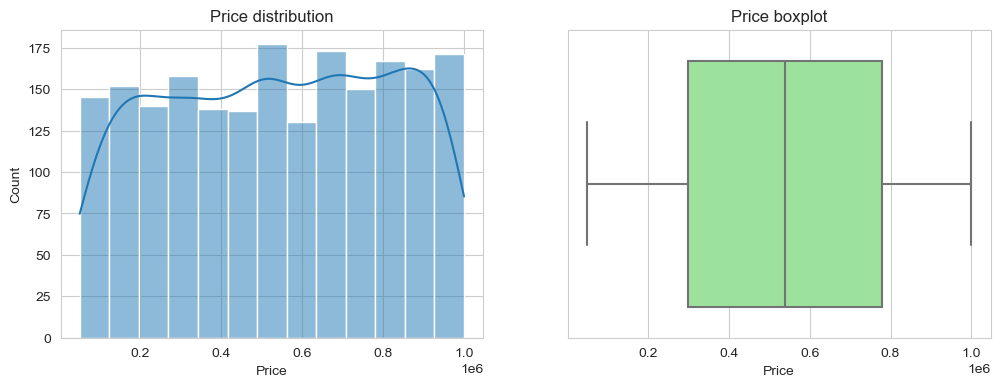

Skewness: -0.06


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], kde=True, ax=ax[0])
ax[0].set_title("Price distribution")
sns.boxplot(x=df["Price"], ax=ax[1], color="lightgreen")
ax[1].set_title("Price boxplot")
plt.show()
print("Skewness:", round(df["Price"].skew(), 2))

## EDA Observations
- The dataset has 2000 houses and 10 columns (7 numeric, 3 categorical).
- There are no missing values in any column.
- Price is spread fairly evenly across its range, without a heavy right tail.
- Categorical features: Location, Condition and Garage.

## Feature Selection Discussion
Features likely to predict price:
- **Area**: larger houses usually cost more.
- **Bedrooms / Bathrooms / Floors**: more rooms and floors mean more usable space.
- **YearBuilt (converted to Age)**: newer houses are usually pricier.
- **Location**: location is a major driver in real estate (e.g. Downtown vs Suburban).
- **Condition**: houses in better condition command higher prices.
- **Garage**: having a garage adds value.
`Id` is only an identifier, so it is dropped.

In [13]:
data = df.drop(columns=["Id"]).copy()

# Age is more meaningful than the raw year
data["Age"] = 2026 - data["YearBuilt"]
data = data.drop(columns=["YearBuilt"])

# One-Hot Encoding for categorical columns
data = pd.get_dummies(data, columns=["Location", "Condition", "Garage"], drop_first=True)

print("Shape after encoding:", data.shape)
print("Remaining nulls:", data.isnull().sum().sum())
data.head()

Shape after encoding: (2000, 13)
Remaining nulls: 0


,Area,Bedrooms,Bathrooms,Floors,Price,Age,Location_Rural,Location_Suburban,Location_Urban,Condition_Fair,Condition_Good,Condition_Poor,Garage_Yes
0,1360,5,4,3,149919,56,False,False,False,False,False,False,False
1,4272,5,4,3,424998,68,False,False,False,False,False,False,False
2,3592,2,2,3,266746,88,False,False,False,False,True,False,False
3,966,4,2,2,244020,124,False,True,False,True,False,False,True
4,4926,1,4,2,636056,51,False,False,False,True,False,False,True


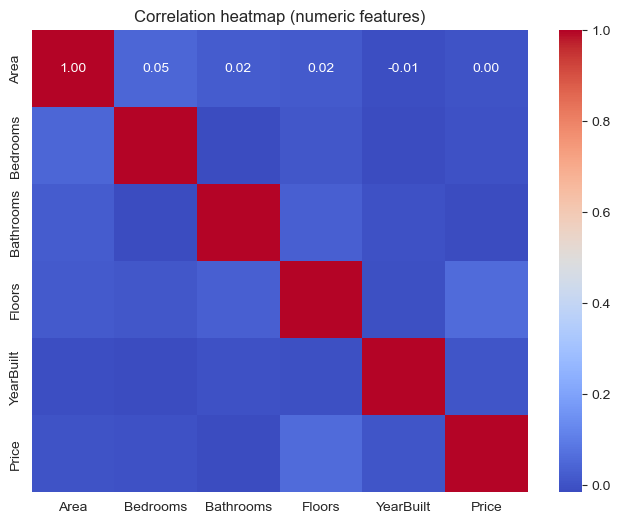

Price        1.000000
Floors       0.055890
YearBuilt    0.004845
Area         0.001542
Bedrooms    -0.003471
Bathrooms   -0.015737
Name: Price, dtype: float64


In [15]:
num_df = df.drop(columns=["Id"]).select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap (numeric features)")
plt.show()

print(num_df.corr()["Price"].sort_values(ascending=False))

The correlations between Price and the numeric features are ___ (look at the heatmap values). Area is the feature most correlated with Price, but the relationship is ___. Predictors do not correlate strongly with each other, so multicollinearity is not a concern.

In [20]:
X = data.drop(columns=["Price"])
y = data["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1600, 12) Test: (400, 12)


In [26]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

In [28]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MSE : {mse:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²  : {r2:.4f}")

MSE : 78,321,466,146.03
RMSE: 279,859.73
R²  : -0.0067


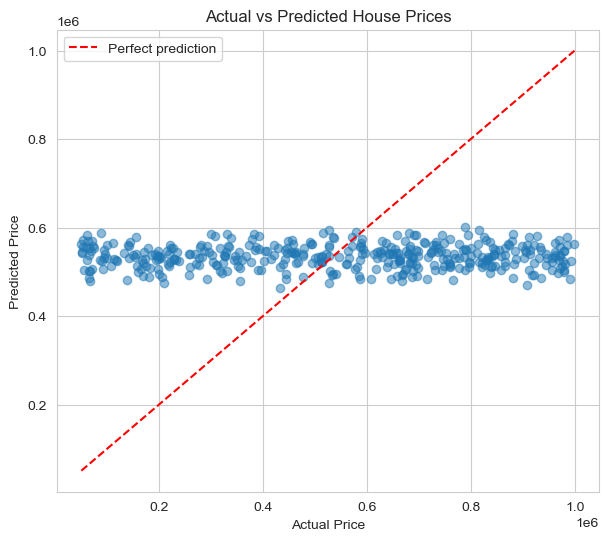

In [30]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()

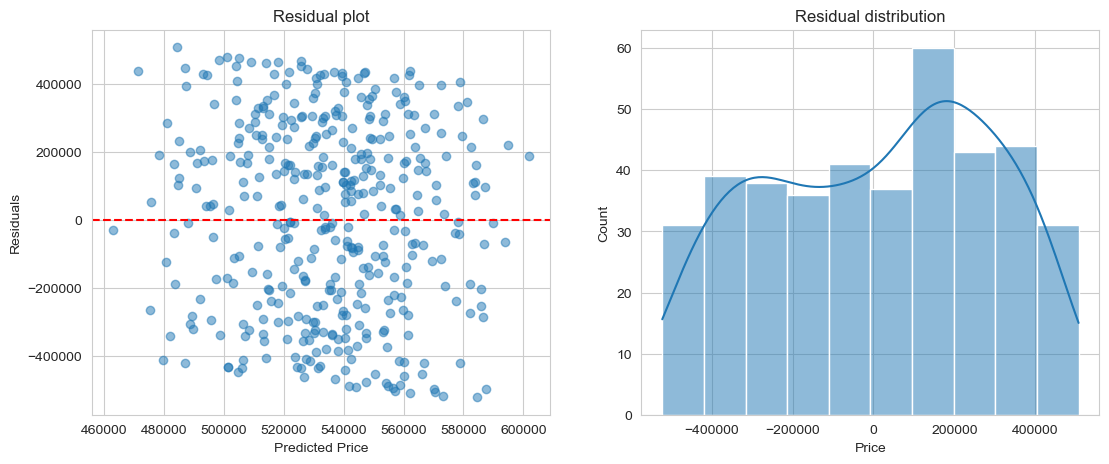

In [32]:
residuals = y_test - y_pred

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_pred, residuals, alpha=0.5)
ax[0].axhline(0, color="red", linestyle="--")
ax[0].set_xlabel("Predicted Price")
ax[0].set_ylabel("Residuals")
ax[0].set_title("Residual plot")
sns.histplot(residuals, kde=True, ax=ax[1])
ax[1].set_title("Residual distribution")
plt.show()

## Model Evaluation
- R² of ___ means the model explains about ___% of the variation in house prices.
- RMSE of ___ means predictions are off by this amount on average.
- In the actual vs predicted plot, the points ___ (are / are not) close to the diagonal.
- Residuals are ___ (randomly scattered / show a pattern) around zero, which tells us whether a linear model is appropriate.

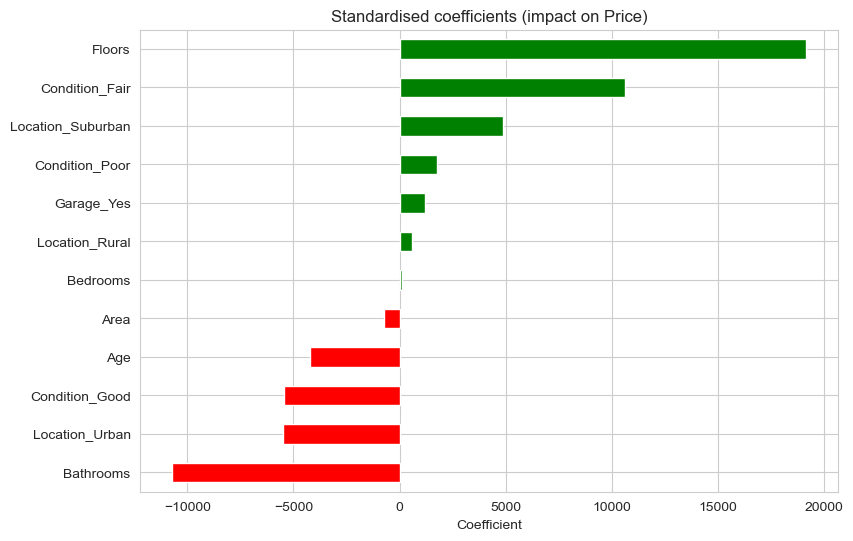

Floors               19148.405610
Condition_Fair       10620.734920
Location_Suburban     4858.400472
Condition_Poor        1778.232367
Garage_Yes            1185.205708
Location_Rural         564.692039
Bedrooms               109.591302
Area                  -748.906099
Age                  -4222.684673
Condition_Good       -5440.814630
Location_Urban       -5484.313686
Bathrooms           -10714.207403
dtype: float64

In [38]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

lr_s = LinearRegression().fit(X_train_s, y_train)
coef = pd.Series(lr_s.coef_, index=X.columns).sort_values()

plt.figure(figsize=(9, 6))
coef.plot(kind="barh", color=["red" if c < 0 else "green" for c in coef])
plt.title("Standardised coefficients (impact on Price)")
plt.xlabel("Coefficient")
plt.show()

coef.sort_values(ascending=False)

Green bars have a positive impact on price and red bars a negative one. The feature with the largest positive coefficient is ___ and the largest negative is ___. Coefficients were computed on standardised features so they can be compared directly.

In [40]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=10, max_iter=10000),
}

results = []
for name, m in models.items():
    m.fit(X_train_s, y_train)
    p = m.predict(X_test_s)
    results.append([name, np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])

pd.DataFrame(results, columns=["Model", "RMSE", "R²"]).round(4)

,Model,RMSE,R²
0,Linear Regression,279859.7258,-0.0067
1,Ridge,279846.7990,-0.0066
2,Lasso,279857.2033,-0.0067


## Conclusion
Linear Regression was trained to predict house prices from area, rooms, age, location, condition and garage. The model achieved R² = ___ and RMSE = ___. Ridge and Lasso gave ___ results, so regularisation ___ (did / did not) improve performance. Limitations: only a few features are available and the relationship may not be purely linear. Future improvements: try tree-based models, add features such as distance to the city centre, and test interaction terms.